---
  title: "Aula 8a - Semantação Semantica"
  author: Qiusheng Wu
  date: 2026-21-10
  categories: [GeoAI, technology]
  image: geoai-py.png
  description: "Notebook extraído do github do livro do prof. Quisheng Wu"
---
# Segmentação semantica

O fluxo mais direto com o `geoai` consiste em utilizar a função `geoai.timm_segmentation_from_hub`. Essa função permite baixar os pesos de um modelo já treinado no Hugging Face Hub e aplicar a inferência em mosaico (*tiled inference*) sobre um recorte local sem necessidade de retreinar a rede.

Abaixo está uma estrutura completa e pronta para notebook (`.ipynb`), dividida por blocos de aula.


### 1: Instalação das Dependências (Colab)


In [ ]:
# Instalação do geoai e dependências de visão computacional/geoprocessamento
!pip install -q geoai-py rasterio matplotlib huggingface_hub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### 2: Importação das Bibliotecas

In [ ]:
import os
import rasterio as rio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import geoai

### 3: Download do Recorte Sentinel-2 (RGB + NIR)

Aqui você pode apontar para o seu repositório (GitHub Releases, Source Cooperative, ou Google Drive público):

In [ ]:
import os
import urllib.request
import rasterio as rio

# 1. URL de origem
s2_url = "https://github.com/Alixandrini/PPEC083/raw/refs/heads/main/sentinel_2/S2_Ilha_de_mare_4b.tif"

# 2. Caminho do arquivo LOCAL que será salvo no Colab
input_raster = "S2_Ilha_de_mare_4b.tif"

# 3. Download explícito salvando com o nome do arquivo local
if not os.path.exists(input_raster):
    print("Baixando o recorte Sentinel-2...")
    urllib.request.urlretrieve(s2_url, input_raster)
    print("Download concluído com sucesso!")
else:
    print("Arquivo local já existente.")

# 4. Inspeção dos metadados locais
with rio.open(input_raster) as src:
    print(f"Arquivo local: {input_raster}")
    print(f"Dimensões: {src.width} x {src.height} pixels")
    print(f"Bandas: {src.count}")
    print(f"CRS: {src.crs}")
    print(f"Resolução espacial: {src.res[0]:.2f} m")

Baixando o recorte Sentinel-2...
Download concluído com sucesso!
Arquivo local: S2_Ilha_de_mare_4b.tif
Dimensões: 828 x 693 pixels
Bandas: 4
CRS: EPSG:32724
Resolução espacial: 10.00 m



### 4: Visualização das Composições (RGB e Falsa-Cor Urbana/Vegetação)

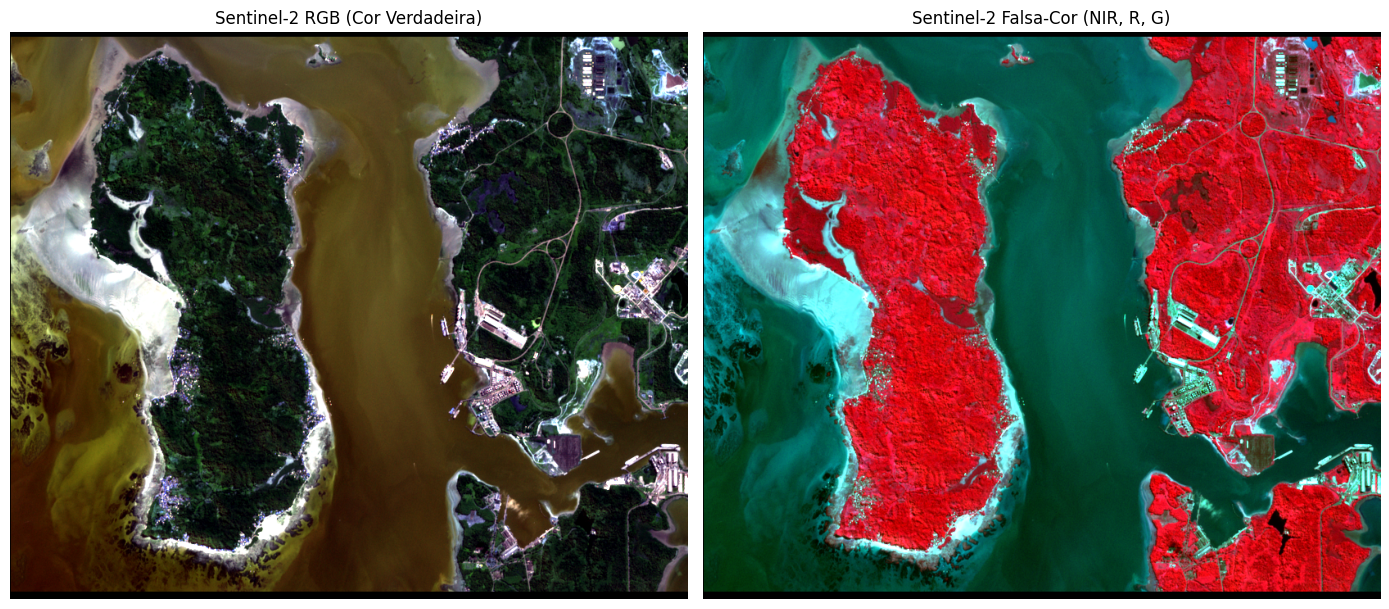

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

with rio.open("S2_Ilha_de_mare_4b.tif") as src:
    # Lê as 4 bandas (1: Red, 2: Green, 3: Blue, 4: NIR)
    data = src.read([1, 2, 3, 4]).astype(np.float32)
    nodata_val = src.nodata

def stretch_robusto(band, nodata=None):
    # Mascara valores inválidos, zeros de fundo e NaNs
    mask_valida = ~np.isnan(band)
    if nodata is not None:
        mask_valida &= (band != nodata)
    mask_valida &= (band > 0)  # Evita zeros de recorte/borda

    # Se a banda inteira for nula, evita divisão por zero
    if not np.any(mask_valida):
        return np.zeros_like(band)

    p2, p98 = np.percentile(band[mask_valida], (2, 98))

    if p98 == p2:
        return np.zeros_like(band)

    normalizado = (band - p2) / (p98 - p2)
    return np.clip(normalizado, 0, 1)

r_norm = stretch_robusto(data[0], nodata_val)
g_norm = stretch_robusto(data[1], nodata_val)
b_norm = stretch_robusto(data[2], nodata_val)
nir_norm = stretch_robusto(data[3], nodata_val)

rgb = np.stack([r_norm, g_norm, b_norm], axis=-1)
cir = np.stack([nir_norm, r_norm, g_norm], axis=-1)

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(rgb)
ax[0].set_title("Sentinel-2 RGB (Cor Verdadeira)")
ax[0].axis("off")

ax[1].imshow(cir)
ax[1].set_title("Sentinel-2 Falsa-Cor (NIR, R, G)")
ax[1].axis("off")

plt.tight_layout()
plt.show()


### 5: Inferência com Modelo Pré-treinado do Hugging Face Hub

O `geoai` baixa a arquitetura e os pesos diretamente via `repo_id` e fatia a imagem em blocos com sobreposição (`overlap`) para evitar linhas de costura:

In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [ ]:
!pip install omniwatermask

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [omniwatermask]


In [ ]:
# Segmentação direta com pesos pré-treinados da biblioteca
s2_mask_path = geoai.segment_water(
    input_raster,
    band_order="naip",
    output_raster="mascara_agua_sentinel.tif",
)

# Segmentação direta com pesos pré-treinados para 4 bandas (Red, Green, Blue, NIR)
gdf_agua = geoai.segment_water(
    input_raster,
    band_order="naip",  # Mapeia Red, Green, Blue, NIR
    output_raster="mascara_agua_sentinel.tif",
    output_vector="poligonos_agua.geojson",
    smooth=True,
    min_size=100,
)

print(f"Total de corpos d'água extraídos: {len(gdf_agua)}")

PM_model_1.5.38_s1s2_water_flair_convnex(…): reconstructing file:   0%|          |  0.00B /  531MB            

PM_model_1.5.38_s1s2_water_flair_convnex(…): downloading bytes:           |  0.00B            

Using cpu:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/omniwatermask/water_inf_helpers.py:278: RuntimeWarning: overflow encountered in cast
  input_bands_tensor = torch.from_numpy(input_bands.astype(np.float16)).to(
/usr/local/lib/python3.13/dist-packages/omnicloudmask/cloud_mask.py:455: UserWarning: Patch size too large, reducing to 693 and overlap to 300.
  patch_overlap, patch_size = check_patch_size(
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:173: RuntimeWarning: overflow encountered in reduce
  arrmean = umr_sum(arr, axis, dtype, keepdims=True, where=where)
/usr/local/lib/python3.13/dist-packages/omnicloudmask/model_utils.py:130: RuntimeWarning: invalid value encountered in divide
  out_array[id][mask] = (masked_values - mean) / std


Using cpu:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/omniwatermask/water_inf_helpers.py:278: RuntimeWarning: overflow encountered in cast
  input_bands_tensor = torch.from_numpy(input_bands.astype(np.float16)).to(
/usr/local/lib/python3.13/dist-packages/omnicloudmask/cloud_mask.py:455: UserWarning: Patch size too large, reducing to 693 and overlap to 300.
  patch_overlap, patch_size = check_patch_size(
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:173: RuntimeWarning: overflow encountered in reduce
  arrmean = umr_sum(arr, axis, dtype, keepdims=True, where=where)
/usr/local/lib/python3.13/dist-packages/omnicloudmask/model_utils.py:130: RuntimeWarning: invalid value encountered in divide
  out_array[id][mask] = (masked_values - mean) / std


Total de corpos d'água extraídos: 6


> **Dica para aula:** Se o modelo estiver em um repositório privado do Hugging Face, basta adicionar antes desta célula:
> ```bash{python}
> import os
> os.environ["HF_TOKEN"] = "hf_..."
> ```



### 6: Exibição dos Resultados com Legenda Temática

Valores únicos na máscara de água: [0 1]


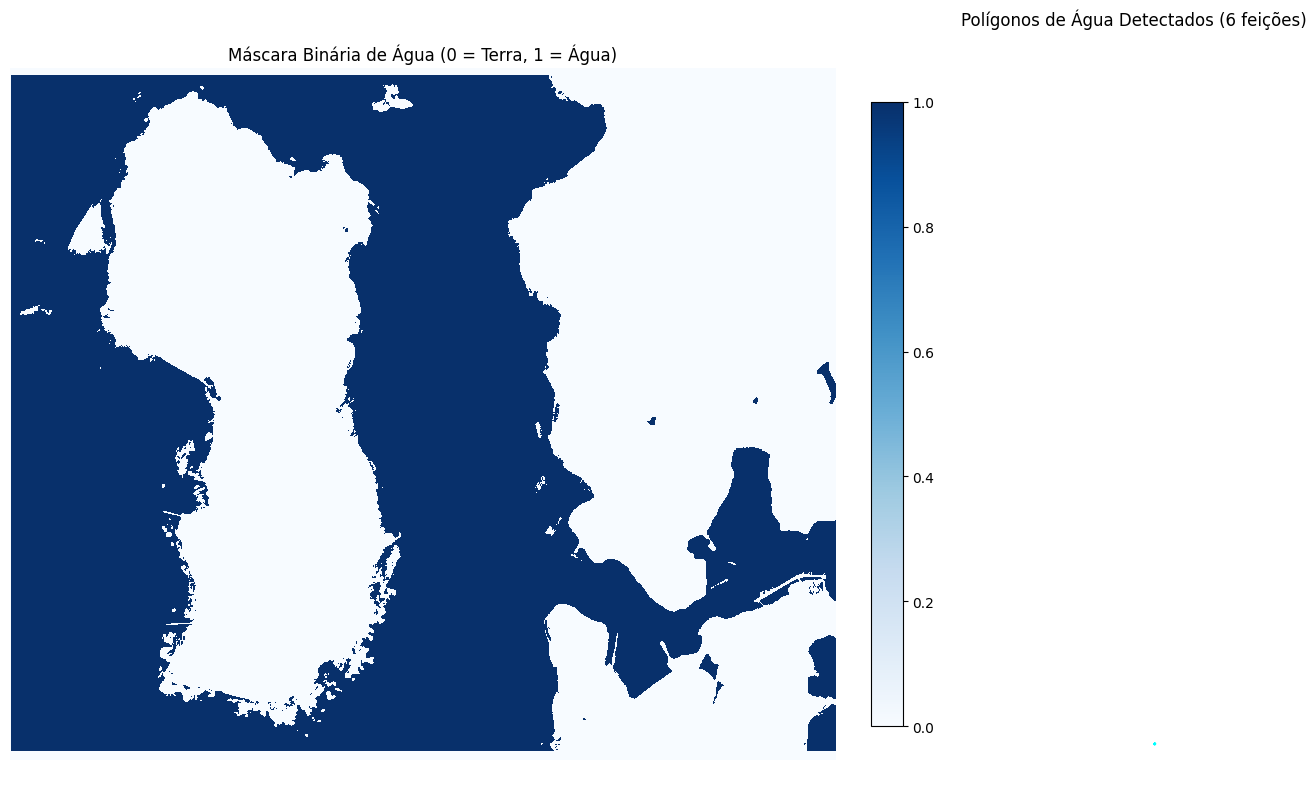

In [ ]:
import geopandas as gpd

# 1. Carrega o raster de máscara gerado pelo segment_water
with rio.open("mascara_agua_sentinel.tif") as src:
    mask_agua = src.read(1)
    print(f"Valores únicos na máscara de água: {np.unique(mask_agua)}")

# 2. Carrega os polígonos geoespaciais
gdf_poligonos = gpd.read_file("poligonos_agua.geojson")

# 3. Plotagem lado a lado: Máscara binária e Polígonos sobrepostos
fig, ax = plt.subplots(1, 2, figsize=(16, 8))

# Painel 1: Máscara binária com escala de cinza/azul
im = ax[0].imshow(mask_agua, cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ax[0].set_title("Máscara Binária de Água (0 = Terra, 1 = Água)")
ax[0].axis("off")
plt.colorbar(im, ax=ax[0], fraction=0.035, pad=0.04)

# Painel 2: Polígonos suavizados sobre o RGB original
ax[1].imshow(rgb)
if len(gdf_poligonos) > 0:
    gdf_poligonos.plot(ax=ax[1], facecolor="none", edgecolor="cyan", linewidth=1.5)
ax[1].set_title(f"Polígonos de Água Detectados ({len(gdf_poligonos)} feições)")
ax[1].axis("off")

plt.tight_layout()
plt.show()